Reverse idea - cluster onn admissions, tryna investigate the rest

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score

In [5]:
PROJECT_ROOT = Path.cwd().parents[0]

DATA_PATH = PROJECT_ROOT / "Data" / "Lumiere_Country_Full_Backup.csv"
CLUSTERS_PATH = (
    PROJECT_ROOT / "outputs" / "text_clustering"
    / "results_content_only" / "clustered_films_k6.csv"
)

df_admissions = pd.read_csv(DATA_PATH)
df_clusters = pd.read_csv(CLUSTERS_PATH)

assert len(df_admissions) == len(df_clusters), "Row count mismatch!"

df = df_admissions.copy()
df["cluster"] = df_clusters["cluster"].values

print(f"Loaded {len(df)} films")

Loaded 2000 films


In [6]:
def parse_country_admissions(value):
    if pd.isna(value) or value == "Not Found":
        return {}
    try:
        return json.loads(value.replace('""', '"'))
    except (json.JSONDecodeError, TypeError):
        return {}

# Build long format first.
records = []
for idx, row in df.iterrows():
    admissions = parse_country_admissions(row["country_admissions"])
    for country, count in admissions.items():
        if country.startswith("Total"):
            continue
        records.append({
            "titleId": row["titleId"],
            "originalTitle": row["originalTitle"],
            "mainCountry": row["mainCountry"],
            "firstLanguage": row["firstLanguage"],
            "genres": row["genres"],
            "keywords": row["keywords"],
            "cluster": row["cluster"],
            "country": country,
            "admissions": count
        })

df_long = pd.DataFrame(records)

# Remove small countries and handle GB/IE overlap (same cleanup as before).
MIN_FILMS = 50
country_film_counts = df_long.groupby("country")["titleId"].nunique()
small_countries = country_film_counts[country_film_counts < MIN_FILMS].index.tolist()
df_long = df_long[~df_long["country"].isin(small_countries)].copy()

films_with_gbie = set(df_long[df_long["country"] == "GB_IE"]["titleId"])
mask_redundant = (
    df_long["country"].isin(["GB", "IE"]) &
    df_long["titleId"].isin(films_with_gbie)
)
df_long = df_long[~mask_redundant].copy()

print(f"Long format: {len(df_long)} rows")
print(f"Countries: {df_long['country'].nunique()}")
print(f"Films: {df_long['titleId'].nunique()}")

Long format: 22297 rows
Countries: 35
Films: 1840


In [7]:
# Pivot: films × countries, raw admissions, fill missing with 0.
admissions_matrix = df_long.pivot_table(
    index="titleId",
    columns="country",
    values="admissions",
    fill_value=0
)

print(f"Full matrix: {admissions_matrix.shape}")

# Convert to percentage of each film's total.
row_totals = admissions_matrix.sum(axis=1)
admissions_pct = admissions_matrix.div(row_totals, axis=0) * 100

# Filter: only films released in enough countries.
MIN_COUNTRIES = 10
countries_per_film = (admissions_matrix > 0).sum(axis=1)
valid_films = countries_per_film[countries_per_film >= MIN_COUNTRIES].index
admissions_pct_filtered = admissions_pct.loc[valid_films]

print(f"Films with {MIN_COUNTRIES}+ countries: {len(admissions_pct_filtered)} / {len(admissions_pct)}")
print(f"Countries: {admissions_pct_filtered.shape[1]}")

# Sanity check.
print(f"\nRow sums (should be ~100): min={admissions_pct_filtered.sum(axis=1).min():.1f}, max={admissions_pct_filtered.sum(axis=1).max():.1f}")

# Example film distribution.
print(f"\nExample film distribution (top 10 countries):")
example = admissions_pct_filtered.iloc[0].sort_values(ascending=False)
print(example.head(10).round(2))

Full matrix: (1840, 35)
Films with 10+ countries: 898 / 1840
Countries: 35

Row sums (should be ~100): min=100.0, max=100.0

Example film distribution (top 10 countries):
country
FR       59.51
IT       10.85
CZ        8.40
GB_IE     8.32
ES        4.45
SK        3.58
FI        1.20
CH        1.16
PL        0.83
RO        0.68
Name: tt0013442, dtype: float64


In [8]:
# Try different k values with KMeans.
K_VALUES = [4, 5, 6, 7, 8, 10]

print(f"Clustering on {admissions_pct_filtered.shape[0]} films × {admissions_pct_filtered.shape[1]} countries\n")

print(f"{'k':<5} {'Silhouette':>10} {'Inertia':>12} {'Smallest':>10} {'Largest':>10} {'Imbalance':>10}")
print("-" * 60)

results = {}
for k in K_VALUES:
    km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    labels = km.fit_predict(admissions_pct_filtered.values)
    
    sil = silhouette_score(admissions_pct_filtered.values, labels, sample_size=min(500, len(labels)), random_state=42)
    sizes = pd.Series(labels).value_counts().sort_index()
    imbalance = sizes.max() / sizes.min()
    
    results[k] = {"model": km, "labels": labels, "silhouette": sil}
    
    print(f"{k:<5} {sil:>10.3f} {km.inertia_:>12.0f} {sizes.min():>10} {sizes.max():>10} {imbalance:>10.1f}")

Clustering on 898 films × 35 countries

k     Silhouette      Inertia   Smallest    Largest  Imbalance
------------------------------------------------------------
4          0.233       730966        129        461        3.6
5          0.255       638310         35        443       12.7
6          0.272       560647         35        414       11.8
7          0.275       515638         34        360       10.6
8          0.256       472588         34        255        7.5
10         0.251       399750         14        213       15.2


In [9]:
# Profile k=6 and k=7.
for k in [6, 7]:
    km = results[k]["model"]
    labels = results[k]["labels"]
    
    # Attach labels to the percentage matrix.
    df_profiles = admissions_pct_filtered.copy()
    df_profiles["adm_cluster"] = labels
    
    print(f"\n{'=' * 70}")
    print(f"ADMISSIONS CLUSTERS: k={k}")
    print(f"{'=' * 70}")
    
    for c in sorted(df_profiles["adm_cluster"].unique()):
        cluster_df = df_profiles[df_profiles["adm_cluster"] == c]
        mean_pct = cluster_df.drop(columns="adm_cluster").mean().sort_values(ascending=False)
        
        print(f"\n--- Cluster {c} ({len(cluster_df)} films) ---")
        print(f"Top countries by mean % of admissions:")
        for country, pct in mean_pct.head(5).items():
            print(f"  {country:<8} {pct:>6.1f}%")
        
        # What content clusters and languages are in here?
        film_info = df[df["titleId"].isin(cluster_df.index)]
        top_langs = film_info["firstLanguage"].value_counts().head(3)
        top_origins = film_info["mainCountry"].value_counts().head(3)
        top_content = film_info["cluster"].value_counts().sort_index()
        
        print(f"Top languages: {', '.join([f'{l} ({c})' for l, c in top_langs.items()])}")
        print(f"Top origins:   {', '.join([f'{o} ({c})' for o, c in top_origins.items()])}")
        print(f"Content clusters: {', '.join([f'c{cl}:{ct}' for cl, ct in top_content.items()])}")


ADMISSIONS CLUSTERS: k=6

--- Cluster 0 (414 films) ---
Top countries by mean % of admissions:
  FR         17.9%
  IT         13.5%
  ES         12.8%
  DE         10.9%
  GB_IE       8.7%
Top languages: en (301), it (20), fr (17)
Top origins:   GB (162), FR (54), DE (40)
Content clusters: c0:58, c1:101, c2:65, c3:65, c4:80, c5:45

--- Cluster 1 (120 films) ---
Top countries by mean % of admissions:
  GB         34.0%
  FR         13.7%
  DE          9.8%
  ES          7.4%
  IT          6.7%
Top languages: en (116), fr (2), zxx (1)
Top origins:   GB (95), IE (10), FR (6)
Content clusters: c0:27, c1:19, c2:22, c3:15, c4:27, c5:10

--- Cluster 2 (131 films) ---
Top countries by mean % of admissions:
  FR         63.2%
  DE          5.3%
  ES          4.9%
  IT          4.3%
  GB_IE       3.8%
Top languages: en (64), fr (47), de (6)
Top origins:   FR (69), GB (25), DE (8)
Content clusters: c0:17, c1:27, c2:27, c3:8, c4:34, c5:18

--- Cluster 3 (40 films) ---
Top countries by mean % of 

As expected, the admissions clusters are largely driven by where the audience concentrates, and the dominant pattern is language/origin. But there are some interesting nuances.
k=7 is more informative than k=6 because it splits out an Italy-dominated cluster (cluster 4) that k=6 absorbs into the general pan-European cluster. Let me focus on k=7:
Cluster 1 (360 films) — the "pan-European" cluster. The largest group by far. Admissions spread relatively evenly across France (19%), Spain (13%), Germany (12%), GB_IE (10%), Italy (9%). These are the true travellers. Almost all English-language, mostly British origin, and content clusters are evenly represented. This is the performance profile every filmmaker wants.
Cluster 0 (131 films) — "GB-heavy." 33% of audience in GB alone. Almost entirely English-language and British-origin. The key difference from cluster 1 is that these films do well in Britain specifically but don't spread as evenly to continental Europe. Probably films with strong British cultural specificity that attract some international distribution but concentrate at home.
Cluster 5 (150 films) — "GB_IE-heavy." 44% in GB_IE. Very similar to cluster 0 but even more concentrated. This is interesting — there are TWO British-audience clusters with different degrees of concentration. Cluster 5 content clusters skew toward c2 (comedy) and c5 (adventure/family), which aligns with our earlier finding that these content types don't travel well.
Cluster 2 (128 films) — "France-dominated." 64% of audience in France. Mix of French-language and English-language films, but overwhelmingly French origin. Content clusters skew toward c4 (romance) and c2 (comedy) — the domestic-heavy content types. These are films that got international release but the audience stayed in France.
Cluster 3 (34 films) — "Spain-dominated." 64% in Spain. Same pattern — a mix of English and Spanish language, Spanish origin. Content skews toward c1 (drama) and c3 (crime thriller). Small cluster, very concentrated.
Cluster 6 (39 films) — "Germany-dominated." 54% in Germany. Mix of English and German language, German origin. Interestingly skews toward c5 (adventure/family) — German-made family films that play mostly at home.
Cluster 4 (56 films) — "Italy-leaning." 39% Italy, the rest spread across France, Spain, Germany. This is the one k=7 separates from k=6. More English-language than Italian, with content skewing toward c2 (comedy). Films that do disproportionately well in Italy without being Italian-domestic products.
The big takeaway: admissions clustering mostly re-discovers language and origin corridors, as we predicted. The clusters are essentially: "pan-European", "British domestic", "very British domestic", "French domestic", "Spanish domestic", "German domestic", and "Italy-leaning." Content cluster membership is surprisingly evenly distributed within most admissions clusters — meaning the same content types appear in every performance pattern.
Where this is genuinely useful is the contrast between cluster 1 and the rest. The 360 pan-European films versus the ~540 domestically-concentrated films is the key split. The question for your predictor becomes: what distinguishes a film that ends up in cluster 1 from one that ends up in cluster 2 or 5? We already know language and origin matter — but within English-language British films, some end up pan-European (cluster 1) and others stay GB-heavy (cluster 0/5). That difference is likely content-driven, and worth digging into.
Want to investigate that — what separates the pan-European British films from the UK-concentrated ones?

In [10]:
k = 20
km = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
labels = km.fit_predict(admissions_pct_filtered.values)

sil = silhouette_score(admissions_pct_filtered.values, labels, sample_size=min(500, len(labels)), random_state=42)
sizes = pd.Series(labels).value_counts().sort_index()

print(f"k={k}, Silhouette: {sil:.3f}")
print(f"\nCluster sizes:")
print(sizes)
print(f"\nSmallest: {sizes.min()}, Largest: {sizes.max()}")

# Profile each cluster.
df_profiles = admissions_pct_filtered.copy()
df_profiles["adm_cluster"] = labels

for c in sorted(df_profiles["adm_cluster"].unique()):
    cluster_df = df_profiles[df_profiles["adm_cluster"] == c]
    mean_pct = cluster_df.drop(columns="adm_cluster").mean().sort_values(ascending=False)
    
    # Top 3 countries with their %
    top3 = ", ".join([f"{country} {pct:.0f}%" for country, pct in mean_pct.head(3).items()])
    
    # Film info.
    film_info = df[df["titleId"].isin(cluster_df.index)]
    top_lang = film_info["firstLanguage"].value_counts().index[0]
    top_origin = film_info["mainCountry"].value_counts().index[0]
    
    print(f"\nCluster {c:>2} ({len(cluster_df):>3} films) | {top3} | lang: {top_lang}, origin: {top_origin}")

k=20, Silhouette: 0.201

Cluster sizes:
0     108
1      71
2      42
3      25
4      89
5      90
6      36
7      22
8      16
9      55
10     10
11     39
12     62
13     58
14     18
15      9
16     90
17     36
18     12
19     10
Name: count, dtype: int64

Smallest: 9, Largest: 108

Cluster  0 (108 films) | GB_IE 22%, FR 18%, DE 15% | lang: en, origin: GB

Cluster  1 ( 71 films) | FR 61%, DE 6%, IT 6% | lang: en, origin: FR

Cluster  2 ( 42 films) | GB 51%, DE 8%, FR 8% | lang: en, origin: GB

Cluster  3 ( 25 films) | IT 51%, FR 8%, ES 7% | lang: en, origin: IT

Cluster  4 ( 89 films) | GB 23%, FR 19%, DE 10% | lang: en, origin: GB

Cluster  5 ( 90 films) | GB_IE 39%, FR 12%, ES 10% | lang: en, origin: GB

Cluster  6 ( 36 films) | GB_IE 64%, FR 8%, ES 7% | lang: en, origin: GB

Cluster  7 ( 22 films) | ES 44%, IT 11%, FR 8% | lang: en, origin: GB

Cluster  8 ( 16 films) | DE 71%, CH 4%, FR 4% | lang: de, origin: DE

Cluster  9 ( 55 films) | DE 11%, IT 11%, FR 9% | lang: en, o

Now we're getting somewhere. With 20 clusters, the language/origin groupings break apart and reveal genuine geographic performance patterns. Let me group them by what they tell us:

**The domestic-dominated clusters (films that stay home):**
- Cluster 17 (36 films) — **French ultra-domestic.** 82% France. French-language, French origin. These barely register anywhere else.
- Cluster 14 (18 films) — **Spanish ultra-domestic.** 78% Spain. Same pattern.
- Cluster 8 (16 films) — **German ultra-domestic.** 71% Germany. Same pattern.
- Cluster 10 (10 films) — **Danish domestic.** 58% Denmark. Small but distinct.

**The UK spectrum — this is the most interesting part.** British films split into five different performance profiles:
- Cluster 6 (36 films) — **UK-locked.** 64% GB_IE. Hardly travels at all.
- Cluster 2 (42 films) — **GB-heavy.** 51% GB (not GB_IE). Slightly different distribution channel.
- Cluster 5 (90 films) — **UK-leaning but some spread.** 39% GB_IE, with some reaching Spain and France.
- Cluster 4 (89 films) — **UK with continental reach.** 23% GB, 19% France, 10% Germany. Starting to travel.
- Cluster 0 (108 films) — **True pan-European from UK.** 22% GB_IE, 18% France, 15% Germany. The most evenly spread British cluster.

This gradient from cluster 6 → 0 is exactly what your predictor needs to understand. Same language, same origin, but wildly different distribution outcomes. The content driving a film from cluster 6 to cluster 0 is the actionable insight.

**The continental corridors — genuinely new findings:**
- Cluster 19 (10 films) — **Nordic cluster.** 20% Denmark, 16% Sweden, 14% Norway. Swedish-language, Swedish origin. These are films that circulate within Scandinavia. Small but distinct.
- Cluster 18 (12 films) — **Benelux cluster.** 32% Netherlands, 16% France, 12% Belgium. English-language but performing in the Low Countries. An unexpected corridor.
- Cluster 15 (9 films) — **Polish cluster.** 51% Poland, 14% France. English-language but Polish origin. Very niche.
- Cluster 12 (62 films) — **Southern European.** 22% France, 21% Italy, 15% Spain. Films that play well in the Mediterranean markets but not in Northern Europe.
- Cluster 9 (55 films) — **The true universals.** 11% Germany, 11% Italy, 9% France — the most evenly spread cluster. No single market dominates. These are the films every market gets roughly equal share of.

**The hybrid clusters:**
- Cluster 1 (71 films) and 16 (90 films) — **French-heavy but travelling.** 61% and 36% France respectively. French origin but with some international reach — cluster 16 is the "French film that partly travels" while cluster 1 is "French film that barely travels."
- Cluster 7 (22 films) — **Spain-leaning international.** 44% Spain but English-language, British origin. British films that happen to resonate in Spain.
- Cluster 3 (25 films) — **Italy-leaning.** 51% Italy, English-language. Films that over-index in Italy.
- Cluster 13 (58 films) — **Spain-leaning pan-European.** 25% Spain, 16% GB_IE, 15% Germany. Broad but with a Spanish tilt.

**The key insight for your project:** cluster 9 (the true universals) and cluster 19 (the Nordic corridor) are the most interesting for follow-up. Cluster 9 contains 55 films that managed to spread almost perfectly evenly across Europe — what do they have in common? And cluster 19 shows a genuine regional corridor that isn't just about language. Want to dig into the content of either of these?

In [11]:
# Detailed profiling of interesting admissions clusters.
INTERESTING_CLUSTERS = [9, 12, 18, 19]

df_profiles = admissions_pct_filtered.copy()
df_profiles["adm_cluster"] = labels

def parse_keywords(value):
    if pd.isna(value) or value == "":
        return []
    return [k.strip().lower() for k in str(value).split(",") if k.strip()]

def parse_genres(value):
    if pd.isna(value) or value == "":
        return []
    return [g.strip().lower() for g in str(value).split(",") if g.strip()]

for c in INTERESTING_CLUSTERS:
    cluster_films = df_profiles[df_profiles["adm_cluster"] == c]
    film_info = df[df["titleId"].isin(cluster_films.index)].copy()
    
    print(f"\n{'=' * 80}")
    print(f"ADMISSIONS CLUSTER {c} — {len(cluster_films)} films")
    print(f"{'=' * 80}")
    
    # Admissions profile.
    mean_pct = cluster_films.drop(columns="adm_cluster").mean().sort_values(ascending=False)
    print(f"\nAudience distribution (top 10 countries):")
    for country, pct in mean_pct.head(10).items():
        bar = "█" * int(pct)
        print(f"  {country:<8} {pct:>5.1f}% {bar}")
    
    # Content cluster distribution.
    content_dist = film_info["cluster"].value_counts().sort_index()
    print(f"\nContent clusters: {', '.join([f'c{cl}: {ct}' for cl, ct in content_dist.items()])}")
    
    # Language and origin.
    print(f"\nLanguages: {', '.join([f'{l} ({c})' for l, c in film_info['firstLanguage'].value_counts().head(5).items()])}")
    print(f"Origins:   {', '.join([f'{o} ({c})' for o, c in film_info['mainCountry'].value_counts().head(5).items()])}")
    
    # Top genres.
    from collections import Counter
    genre_counter = Counter()
    for genres in film_info["genres"].apply(parse_genres):
        genre_counter.update(genres)
    print(f"\nTop genres: {', '.join([f'{g} ({c})' for g, c in genre_counter.most_common(8)])}")
    
    # Top keywords (excluding very generic ones).
    generic_kw = {"murder", "death", "blood", "violence", "female nudity", "male nudity", 
                  "kiss", "flashback", "cigarette smoking", "photograph", "telephone call",
                  "husband wife relationship", "father son relationship", "mother son relationship",
                  "father daughter relationship", "mother daughter relationship", "dog"}
    
    kw_counter = Counter()
    for kws in film_info["keywords"].apply(parse_keywords):
        kw_counter.update(kws)
    
    filtered_kw = [(k, c) for k, c in kw_counter.most_common(50) if k not in generic_kw][:15]
    print(f"\nDistinctive keywords: {', '.join([f'{k} ({c})' for k, c in filtered_kw])}")
    
    # Release year range.
    years = film_info["releaseYear"].dropna()
    print(f"\nYear range: {int(years.min())}–{int(years.max())}, median: {int(years.median())}")
    
    # Sample films.
    sample = film_info.sample(n=min(8, len(film_info)), random_state=42)
    print(f"\nSample films:")
    for _, row in sample.iterrows():
        title = row["originalTitle"]
        year = int(row["releaseYear"]) if pd.notna(row["releaseYear"]) else "?"
        origin = row["mainCountry"]
        lang = row["firstLanguage"]
        genres = row["genres"] if pd.notna(row["genres"]) else ""
        print(f"  {title} ({year}) [{origin}/{lang}] — {genres[:60]}")


ADMISSIONS CLUSTER 9 — 55 films

Audience distribution (top 10 countries):
  DE        11.5% ███████████
  IT        11.2% ███████████
  FR         9.3% █████████
  ES         7.8% ███████
  PL         7.6% ███████
  GB         7.5% ███████
  NL         6.2% ██████
  RO         4.5% ████
  CZ         3.8% ███
  HU         3.3% ███

Content clusters: c0: 8, c1: 9, c2: 4, c3: 13, c4: 10, c5: 11

Languages: en (44), ga (2), el (2), hu (1), cmn (1)
Origins:   GB (18), DK (7), IE (7), FI (5), IT (3)

Top genres: drama (35), comedy (23), thriller (16), horror (15), crime (14), action (13), adventure (11), romance (7)

Distinctive keywords: shot to death (21), knife (20), written by director (20), escape (17), family relationships (17), slow motion scene (17), fear (16), prologue (15), deception (15), f word (15), gun (15), corpse (14), mirror (14), kidnapping (14), shot in the head (14)

Year range: 1972–2024, median: 2017

Sample films:
  Svetat e golyam i spasenie debne otvsyakade (2008) 

These four clusters reveal genuinely different performance archetypes. Let me break them down:

**Cluster 9 (55 films) — "The True Universals"**

This is the most evenly distributed cluster in the entire dataset. Germany, Italy, France, Spain, Poland, GB, Netherlands all sit between 6-12% — no single market dominates. What unites these films? They're predominantly English-language but from diverse origins: Denmark, Ireland, Finland alongside Britain. Content clusters are almost perfectly evenly spread, meaning no single genre defines this group. The sample films are revealing: The House That Jack Built, Kinds of Kindness, Nymphomaniac, Operation Fortune — these are mid-budget auteur films or genre-bending productions with strong directorial identities. The distinctive keywords (knife, escape, fear, slow motion, f-word) suggest edgy, adult-oriented content. Median year 2017 means this is a modern phenomenon. The profile is: English-language, director-driven, provocative adult content from non-major-studio origins that spreads evenly because it doesn't belong to any single cultural tradition. No country claims it as "theirs", so every country gives it roughly equal attention.

**Cluster 12 (62 films) — "The Southern European Circuit"**

France (23%), Italy (21%), Spain (15%) account for nearly 60% of the audience. These films reach Northern Europe but at much lower rates. Content skews heavily toward drama (48), romance (18), and thriller (21) — cluster c4 (romance/literary) is the single most common content type. Keywords like "surprise ending", "sex scene", "based on novel", "female protagonist" paint a picture: these are sophisticated, literary, often sexually frank dramas. The sample confirms it: Eastern Promises, The Counselor, The Human Stain — dark, adult, character-driven films. Median year 2004, older than cluster 9. The profile suggests that Southern European markets share an appetite for mature, plot-driven drama that Northern and Eastern Europe is less interested in. This is a genuine cultural corridor beyond just language.

**Cluster 18 (12 films) — "The Benelux Magnet"**

The most unexpected cluster. Netherlands (32%), France (16%), Belgium (12%) — over 60% concentrated in three neighbouring countries. Only 12 films, but the content is fascinating: Once Upon a Time in the West, Novecento, Zwartboek, Howards End, Three Colours: White. These are art-house classics and prestige European productions spanning 1968 to 2020 with a median of 1993. Multiple languages (English, Italian, Dutch, Swedish, Polish), multiple origins. There's no obvious language or origin explanation for why these films concentrate in the Benelux region. The keywords (explosion, boat, revenge, based on novel, independent film) don't reveal a clear pattern either. This might reflect the Benelux market's historically strong art-house distribution infrastructure — these countries have proportionally more art-house cinemas and a cultural appetite for "important" European films. Small cluster but a genuine discovery.

**Cluster 19 (10 films) — "The Nordic Circuit"**

Denmark (20%), Sweden (16%), Norway (14%) — 50% in Scandinavia. Languages are mixed: Swedish, Norwegian, Danish, English, Russian, French. Origins too: Sweden, France, Norway, Denmark, UK. The sample films are the giveaway: Millennium trilogy (Flickan som lekte med elden, Luftslottet som sprängdes), Utøya 22. juli, Lilja 4-ever, Hævnen. These are dark Scandinavian dramas and thrillers — socially conscious, often violent, dealing with revenge, justice, and trauma. Content cluster c1 (serious drama/war/biography) dominates. Keywords like "revenge", "pregnancy", "tattoo", "female protagonist", "cell phone" paint the Nordic noir profile. What's interesting is that Spain (10%) and Germany (8%) appear as secondary markets — Nordic noir has a specific continental audience beyond Scandinavia. And the cluster includes non-Nordic films (Another Year from GB, Revenge from France) that apparently share the same audience profile, suggesting it's the *tone and themes* that attract Nordic-oriented audiences, not just Scandinavian origin.

**The overarching insight for your predictor:** these clusters show that European cinema has genuine regional circuits that operate on cultural taste rather than just language. The Southern European circuit (France-Italy-Spain) rewards literary adult drama. The Nordic circuit rewards dark, socially conscious thrillers. The Benelux corridor absorbs prestige art-house. And the universal cluster achieves even distribution through provocative auteur content in English. These circuits could become a feature in your predictor — instead of just "target market: Germany", you could model "target circuit: Southern European" as an intermediate variable.


**Will film travel or will it stay domestic?**

Films: 898

Universality distribution:
count    898.000
mean       0.641
std        0.142
min        0.083
25%        0.586
50%        0.682
75%        0.738
max        0.886
Name: universality, dtype: float64


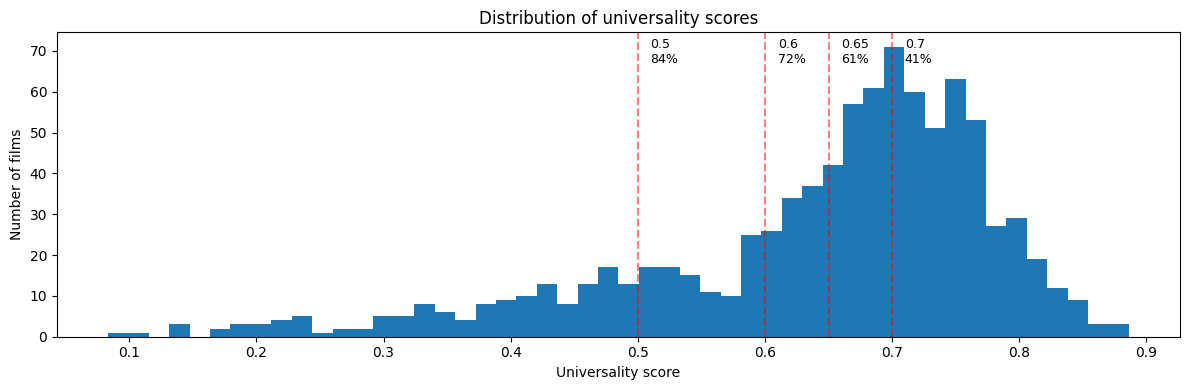


Films above each threshold:
  ≥0.5: 755 films (84.1%)
  ≥0.6: 650 films (72.4%)
  ≥0.65: 550 films (61.2%)
  ≥0.7: 369 films (41.1%)


In [12]:
# We have the admissions percentage matrix and the k=20 clusters.
# But let's define "travels" more simply using the universality score.

# Recompute universality for the filtered films.
from scipy.stats import entropy

universality = {}
for title_id in admissions_pct_filtered.index:
    row = admissions_matrix.loc[title_id]
    nonzero = row[row > 0]
    shares = nonzero / nonzero.sum()
    ent = entropy(shares)
    max_ent = np.log(len(shares))
    universality[title_id] = ent / max_ent if max_ent > 0 else 0

df_univ = pd.DataFrame({
    "titleId": list(universality.keys()),
    "universality": list(universality.values())
})

# Merge with film info.
df_univ = df_univ.merge(df[["titleId", "originalTitle", "mainCountry", "firstLanguage", 
                             "genres", "keywords", "cluster", "imdbRating", "runtimeMinutes"]], 
                        on="titleId", how="left")

print(f"Films: {len(df_univ)}")
print(f"\nUniversality distribution:")
print(df_univ["universality"].describe().round(3))

# Where should we draw the line?
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(df_univ["universality"], bins=50, edgecolor="none")
ax.set_xlabel("Universality score")
ax.set_ylabel("Number of films")
ax.set_title("Distribution of universality scores")

# Show some candidate thresholds.
for threshold in [0.5, 0.6, 0.65, 0.7]:
    n_above = (df_univ["universality"] >= threshold).sum()
    pct = n_above / len(df_univ) * 100
    ax.axvline(x=threshold, color="red", linestyle="--", alpha=0.5)
    ax.text(threshold + 0.01, ax.get_ylim()[1] * 0.9, f"{threshold}\n{pct:.0f}%", fontsize=9)

plt.tight_layout()
plt.show()

print("\nFilms above each threshold:")
for threshold in [0.5, 0.6, 0.65, 0.7]:
    n = (df_univ["universality"] >= threshold).sum()
    print(f"  ≥{threshold}: {n} films ({n/len(df_univ)*100:.1f}%)")

In [13]:
THRESHOLD = 0.65

df_univ["travels"] = (df_univ["universality"] >= THRESHOLD).astype(int)

print(f"Threshold: {THRESHOLD}")
print(f"Travels:     {df_univ['travels'].sum()} ({df_univ['travels'].mean()*100:.1f}%)")
print(f"Stays home:  {(1 - df_univ['travels']).sum()} ({(1 - df_univ['travels']).mean()*100:.1f}%)")

# Quick check: what do the two groups look like?
for label, name in [(1, "TRAVELS"), (0, "STAYS HOME")]:
    subset = df_univ[df_univ["travels"] == label]
    top_langs = subset["firstLanguage"].value_counts().head(3)
    top_origins = subset["mainCountry"].value_counts().head(3)
    
    print(f"\n{name} ({len(subset)} films):")
    print(f"  Languages: {', '.join([f'{l} ({c})' for l, c in top_langs.items()])}")
    print(f"  Origins:   {', '.join([f'{o} ({c})' for o, c in top_origins.items()])}")
    print(f"  Mean IMDb: {subset['imdbRating'].mean():.2f}")
    print(f"  Mean runtime: {subset['runtimeMinutes'].mean():.0f} min")

Threshold: 0.65
Travels:     550 (61.2%)
Stays home:  348 (38.8%)

TRAVELS (550 films):
  Languages: en (460), fr (16), it (13)
  Origins:   GB (277), DE (59), FR (57)
  Mean IMDb: 6.56
  Mean runtime: 109 min

STAYS HOME (348 films):
  Languages: en (220), fr (53), de (23)
  Origins:   GB (138), FR (84), DE (40)
  Mean IMDb: 6.77
  Mean runtime: 108 min


Classifier for traveller vs domestic

In [14]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Build features.
def parse_keywords(value):
    if pd.isna(value) or value == "":
        return []
    return [k.strip().lower() for k in str(value).split(",") if k.strip()]

def parse_genres(value):
    if pd.isna(value) or value == "":
        return []
    return [g.strip().lower() for g in str(value).split(",") if g.strip()]

# Language dummies.
lang_dummies = pd.get_dummies(df_univ["firstLanguage"], prefix="lang")

# Origin dummies.
origin_dummies = pd.get_dummies(df_univ["mainCountry"], prefix="origin")

# Content cluster dummies.
cluster_dummies = pd.get_dummies(df_univ["cluster"], prefix="cluster")

# Genre dummies.
all_genres = set()
for g_list in df_univ["genres"].apply(parse_genres):
    all_genres.update(g_list)

genre_dummies = pd.DataFrame(0, index=df_univ.index, columns=[f"genre_{g}" for g in sorted(all_genres)])
for i, g_list in enumerate(df_univ["genres"].apply(parse_genres)):
    for g in g_list:
        col = f"genre_{g}"
        if col in genre_dummies.columns:
            genre_dummies.iloc[i, genre_dummies.columns.get_loc(col)] = 1

# Top keywords (use the divisive ones we identified earlier).
top_kw = ["blockbuster", "villain", "hero", "monster", "creature", "british",
           "trust", "laughter", "countryside", "crucifix", "ritual", "locked door",
           "remake", "live action", "damsel in distress", "impersonation",
           "marriage proposal", "rainstorm", "underwear", "cult film",
           "based on true story", "independent film", "based on novel",
           "escape", "mission", "espionage", "seduction", "trauma"]

kw_dummies = pd.DataFrame(0, index=df_univ.index, columns=[f"kw_{k}" for k in top_kw])
for i, kw_list in enumerate(df_univ["keywords"].apply(parse_keywords)):
    for kw in kw_list:
        col = f"kw_{kw}"
        if col in kw_dummies.columns:
            kw_dummies.iloc[i, kw_dummies.columns.get_loc(col)] = 1

# Numeric features.
numeric = df_univ[["imdbRating", "runtimeMinutes"]].fillna(df_univ[["imdbRating", "runtimeMinutes"]].median())

# Combine all.
X = pd.concat([lang_dummies, origin_dummies, cluster_dummies, genre_dummies, kw_dummies, numeric], axis=1)
y = df_univ["travels"].values

print(f"Feature matrix: {X.shape}")
print(f"Target balance: {y.mean():.3f} (travels)")

# Split.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {len(X_train)}, Test: {len(X_test)}")

# Try three models.
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, C=0.1, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=10, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, min_samples_leaf=10, random_state=42)
}

print(f"\n{'Model':<25} {'Train Acc':>10} {'Test Acc':>10} {'Test AUC':>10}")
print("-" * 58)

best_model = None
best_auc = 0

for name, model in models.items():
    model.fit(X_train, y_train)
    
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)
    test_proba = model.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, test_proba)
    
    marker = ""
    if test_auc > best_auc:
        best_auc = test_auc
        best_model = (name, model)
        marker = " ← best"
    
    print(f"{name:<25} {train_acc:>10.3f} {test_acc:>10.3f} {test_auc:>10.3f}{marker}")

# Detailed results for best model.
print(f"\n\nBest model: {best_model[0]}")
y_pred = best_model[1].predict(X_test)
print(f"\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stays home", "Travels"]))

Feature matrix: (898, 110)
Target balance: 0.612 (travels)
Train: 718, Test: 180

Model                      Train Acc   Test Acc   Test AUC
----------------------------------------------------------
Logistic Regression            0.703      0.622      0.654 ← best
Random Forest                  0.688      0.644      0.675 ← best
Gradient Boosting              0.813      0.672      0.691 ← best


Best model: Gradient Boosting

Classification report:
              precision    recall  f1-score   support

  Stays home       0.60      0.49      0.54        70
     Travels       0.71      0.79      0.75       110

    accuracy                           0.67       180
   macro avg       0.65      0.64      0.64       180
weighted avg       0.66      0.67      0.66       180



In [15]:
# Feature importance from Gradient Boosting.
feat_imp = pd.DataFrame({
    "feature": X.columns,
    "importance": best_model[1].feature_importances_
}).sort_values("importance", ascending=False)

print("Top 25 most important features:")
print(feat_imp.head(25).to_string(index=False))

print(f"\n\nFeature importance by block:")
def categorize(name):
    if name.startswith("lang_"): return "language"
    if name.startswith("origin_"): return "origin"
    if name.startswith("cluster_"): return "content cluster"
    if name.startswith("genre_"): return "genre"
    if name.startswith("kw_"): return "keyword"
    return "numeric"

feat_imp["block"] = feat_imp["feature"].apply(categorize)
print(feat_imp.groupby("block")["importance"].sum().sort_values(ascending=False).round(4))

Top 25 most important features:
               feature  importance
        runtimeMinutes    0.226695
               lang_en    0.126489
            imdbRating    0.126199
             origin_FR    0.070190
             genre_war    0.049718
             kw_escape    0.042518
             origin_DE    0.028991
           genre_drama    0.027637
          genre_action    0.026227
            kw_mission    0.023378
        genre_thriller    0.021445
             cluster_3    0.015303
             origin_GB    0.014838
kw_based on true story    0.012926
               lang_es    0.012769
           kw_laughter    0.011323
             cluster_2    0.010000
        kw_blockbuster    0.009237
               lang_it    0.009058
               lang_de    0.008710
          genre_sci-fi    0.007712
   kw_independent film    0.007666
      kw_impersonation    0.007297
               lang_fr    0.007157
         genre_fantasy    0.006500


Feature importance by block:
block
numeric            0.

This is more interesting than the accuracy suggested. The model isn't just relying on language — it's using a diverse mix of features.

**Runtime is the single most important feature (23%).** We dismissed it earlier because mean runtime was identical for both classes — but gradient boosting captures nonlinear effects. There's probably a sweet spot: very short films (art-house) and very long films (auteur epics) stay domestic, while standard 90-120 minute films travel better. Let's verify:

```python
# What is runtime doing?
fig, ax = plt.subplots(figsize=(10, 4))

for label, name, color in [(1, "Travels", "steelblue"), (0, "Stays home", "coral")]:
    subset = df_univ[df_univ["travels"] == label]["runtimeMinutes"].dropna()
    ax.hist(subset, bins=30, alpha=0.5, label=name, color=color, density=True)

ax.set_xlabel("Runtime (minutes)")
ax.set_ylabel("Density")
ax.set_title("Runtime distribution: travels vs stays home")
ax.legend()
plt.tight_layout()
plt.show()

# Binned comparison.
df_univ["runtime_bin"] = pd.cut(df_univ["runtimeMinutes"], bins=[0, 80, 95, 110, 130, 300])
print(df_univ.groupby("runtime_bin")["travels"].mean().round(3))
```

But beyond runtime, the feature block breakdown tells a good story:

**Language (16%) matters but isn't dominant.** English is the second most important single feature. The model needs it but doesn't rely on it exclusively.

**Genre (19%) is actually the second most important block.** War, drama, action, thriller, sci-fi, fantasy — these contribute collectively more than language. War films apparently travel (think Dunkirk, 1917 — universal human stories with spectacle). This is something our z-score predictor couldn't capture as cleanly.

**Keywords (15%) add real signal.** "Escape" and "mission" are strong travel indicators — action-oriented, plot-driven keywords. "Laughter" hurts travelability (confirming our earlier finding). "Based on true story" and "blockbuster" help. "Independent film" hurts. These are actionable.

**Origin (11%) is meaningful.** French origin is the strongest negative signal after language. German origin also predicts staying home. British origin mildly helps.

**Content clusters (3%) barely matter.** This confirms what we suspected — the broad content clusters are too coarse to distinguish travellers from non-travellers. It's the finer-grained features (specific genres, specific keywords) that do the work.

**The practical insight:** if you want a film to travel, the recipe from this model is: shoot in English, keep it 90-120 minutes, lean toward action/thriller/war/sci-fi genres, include plot-driven keywords (escape, mission, blockbuster), avoid comedy/drama-only genre tags, and avoid "independent film" positioning. That's more specific and actionable than "make a horror film," which is what the content clusters alone told us.

Want to look at the runtime distribution, or move on to something else?

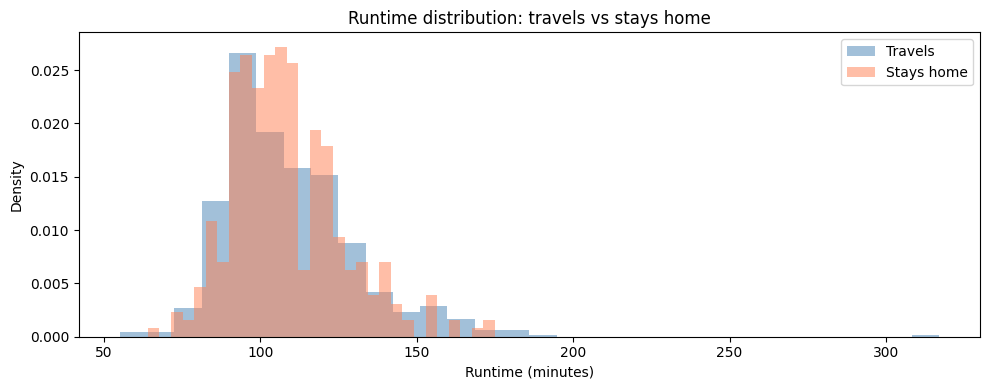

runtime_bin
(0, 80]       0.600
(80, 95]      0.655
(95, 110]     0.548
(110, 130]    0.635
(130, 300]    0.649
Name: travels, dtype: float64


In [16]:
# What is runtime doing?
fig, ax = plt.subplots(figsize=(10, 4))

for label, name, color in [(1, "Travels", "steelblue"), (0, "Stays home", "coral")]:
    subset = df_univ[df_univ["travels"] == label]["runtimeMinutes"].dropna()
    ax.hist(subset, bins=30, alpha=0.5, label=name, color=color, density=True)

ax.set_xlabel("Runtime (minutes)")
ax.set_ylabel("Density")
ax.set_title("Runtime distribution: travels vs stays home")
ax.legend()
plt.tight_layout()
plt.show()

# Binned comparison.
df_univ["runtime_bin"] = pd.cut(df_univ["runtimeMinutes"], bins=[0, 80, 95, 110, 130, 300])
print(df_univ.groupby("runtime_bin")["travels"].mean().round(3))

Overall, shitttttt :(